<a href="https://colab.research.google.com/github/kiplimoowen-cmyk/Ext/blob/main/Summative_Forest_Done.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Summative Lab: Forest Fires Prevention

### Step 1: Load the Dataset

*   Install and import the ucimlrepo library.
*   Load the Forest Fires dataset:
 *   Predictors: Features from forest_fires.data.features.
 *   Target: forest_fires.data.targets.

In [ ]:
# Run pip install if necessary to access the UCI ML Repository (uncomment the next line)
# ! pip install ucimlrepo

!pip install ucimlrepo

In [ ]:
# Data
from ucimlrepo import fetch_ucirepo


forest_fires = fetch_ucirepo(id=162)
X = forest_fires.data.features
y = forest_fires.data.targets


print(X.info())
print(X.describe())
print(y.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    object 
 3   day     517 non-null    object 
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
dtypes: float64(7), int64(3), object(2)
memory usage: 48.6+ KB
None
                X           Y        FFMC         DMC          DC         ISI  \
count  517.000000  517.000000  517.000000  517.000000  517.000000  517.000000   
mean     4.669246    4.299807   90.644681  110.872340  547.940039    9.021663   
std      2.313778    1.229900    5.520111   64.046482  248.066192 

### Step 2: EDA

* Examine the dataset structure and summary statistics.
* Analyze correlations between predictors and the target variable.
* Plot scatterplots for key predictors vs. the target.
* Generate a residual plot to check for randomness in residuals.

In [ ]:
# Examine the structure of the dataset
print("Shape of predictors:", X.shape)
print("Shape of target:", y.shape)

print("\nPredictor columns:")
print(X.columns)

print("\nTarget column:")
print(y.columns)

print("\nData types:")
print(X.dtypes)

Shape of predictors: (517, 12)
Shape of target: (517, 1)

Predictor columns:
Index(['X', 'Y', 'month', 'day', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH',
       'wind', 'rain'],
      dtype='object')

Target column:
Index(['area'], dtype='object')

Data types:
X          int64
Y          int64
month     object
day       object
FFMC     float64
DMC      float64
DC       float64
ISI      float64
temp     float64
RH         int64
wind     float64
rain     float64
dtype: object


In [ ]:
X.describe()

,X,Y,FFMC,DMC,DC,ISI,temp,RH,wind,rain
count,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000
mean,4.669246,4.299807,90.644681,110.872340,547.940039,9.021663,18.889168,44.288201,4.017602,0.021663
std,2.313778,1.229900,5.520111,64.046482,248.066192,4.559477,5.806625,16.317469,1.791653,0.295959
min,1.000000,2.000000,18.700000,1.100000,7.900000,0.000000,2.200000,15.000000,0.400000,0.000000
25%,3.000000,4.000000,90.200000,68.600000,437.700000,6.500000,15.500000,33.000000,2.700000,0.000000
50%,4.000000,4.000000,91.600000,108.300000,664.200000,8.400000,19.300000,42.000000,4.000000,0.000000
75%,7.000000,5.000000,92.900000,142.400000,713.900000,10.800000,22.800000,53.000000,4.900000,0.000000
max,9.000000,9.000000,96.200000,291.300000,860.600000,56.100000,33.300000,100.000000,9.400000,6.400000


In [ ]:
# Check for missing values
print("Missing values in predictors:")
print(X.isnull().sum())

print("\nMissing values in target:")
print(y.isnull().sum())

Missing values in predictors:
X        0
Y        0
month    0
day      0
FFMC     0
DMC      0
DC       0
ISI      0
temp     0
RH       0
wind     0
rain     0
dtype: int64

Missing values in target:
area    0
dtype: int64


In [ ]:
import numpy as np

In [ ]:
#Select numeric predictors
X_numeric = X.select_dtypes(include=np.number)

#Combine numeric predictors with the target
eda_data = X_numeric.copy()
eda_data["area"] = y["area"]

#Calculate correlations
correlations = eda_data.corr()

#Display correlations with the target
print("Correlations with burned area:")
print(correlations["area"].sort_values(ascending=False))

Correlations with burned area:
area    1.000000
temp    0.097844
DMC     0.072994
X       0.063385
DC      0.049383
Y       0.044873
FFMC    0.040122
wind    0.012317
ISI     0.008258
rain   -0.007366
RH     -0.075519
Name: area, dtype: float64



The correlations show that none of the predictors have a strong relationship with burned area. Temperature has the highest positive correlation (0.098), while relative humidity has a weak negative correlation (-0.076). This suggests that predicting burned area may be challenging using individual variables alone.


In [ ]:
import matplotlib.pyplot as plt


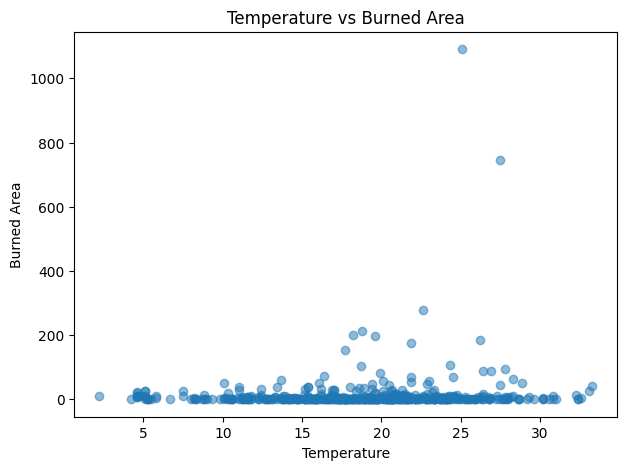

In [ ]:
# Temperature vs Burned Area
plt.figure(figsize=(7, 5))
plt.scatter(X["temp"], y["area"], alpha=0.5)

plt.xlabel("Temperature")
plt.ylabel("Burned Area")
plt.title("Temperature vs Burned Area")

plt.show()


The scatterplot shows a weak relationship between temperature and burned area with the data points widely scattered which supports the correlation analysis which showed that temperature has only a weak positive relationship with burned area.


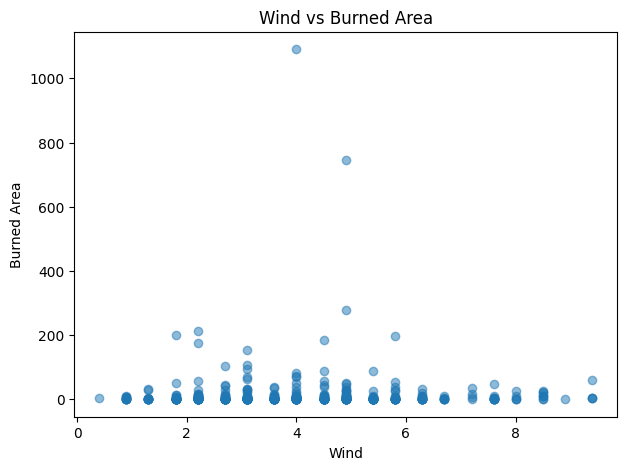

In [ ]:
# Wind vs Burned Area
plt.figure(figsize=(7, 5))
plt.scatter(X["wind"], y["area"], alpha=0.5)

plt.xlabel("Wind")
plt.ylabel("Burned Area")
plt.title("Wind vs Burned Area")

plt.show()

The scatterplot shows a very weak relationship between wind speed and burned area with the points widely scattered which agrees with the correlation resul showing almost no correlation between wind and burned area.


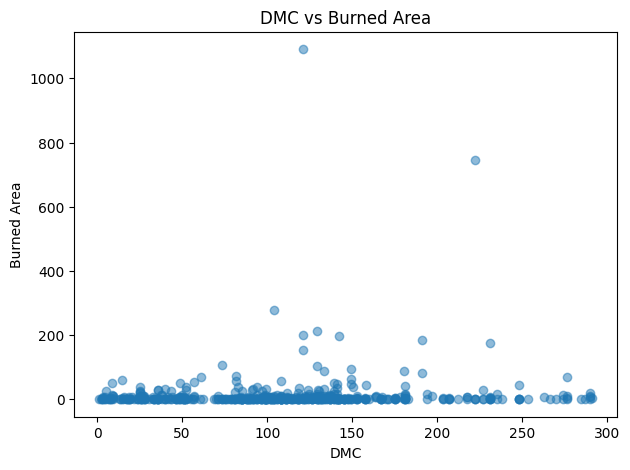

In [ ]:
# DMC vs Burned Area
plt.figure(figsize=(7, 5))
plt.scatter(X["DMC"], y["area"], alpha=0.5)

plt.xlabel("DMC")
plt.ylabel("Burned Area")
plt.title("DMC vs Burned Area")

plt.show()

The scatterplot shows a weak positive relationship between DMC and burned area but the data points are widely scattered, this suggests that DMC alone is not a strong predictor of burned area.


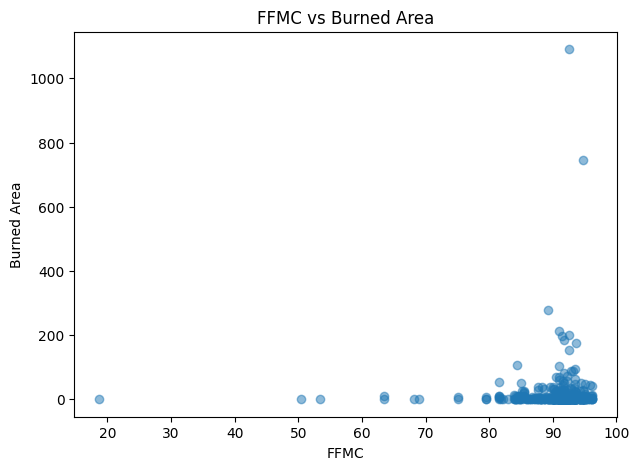

In [ ]:
# FFMC vs Burned Area
plt.figure(figsize=(7, 5))
plt.scatter(X["FFMC"], y["area"], alpha=0.5)

plt.xlabel("FFMC")
plt.ylabel("Burned Area")
plt.title("FFMC vs Burned Area")

plt.show()

The scatterplot shows that most observations are concentrated at high FFMC values with relatively small burned areas however, a few extreme burned area values are present suggesting a weak overall relationship and the presence of outliers.

In [ ]:
from sklearn.linear_model import LinearRegression

# Create the baseline regression model
baseline_model = LinearRegression()

# Fit the model
baseline_model.fit(X_numeric, y["area"])

# Make predictions
predictions = baseline_model.predict(X_numeric)

# Calculate residuals
residuals = y["area"] - predictions

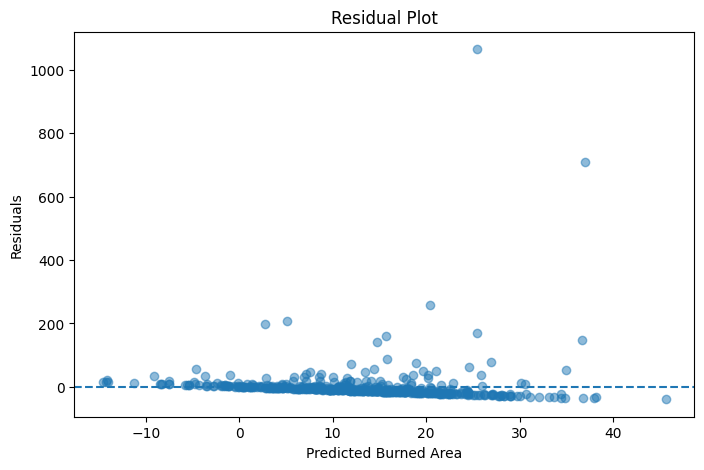

In [ ]:
# Create residual plot
plt.figure(figsize=(8, 5))

plt.scatter(predictions, residuals, alpha=0.5)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Burned Area")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

The residuals are not evenly distributed around zero and a few large positive residuals are visible which suggests the model struggles to predict some extreme burned areas and may not fully meet the assumptions of linear regression.

### Step 3: Fit the regression models

* Fit a baseline multiple linear regression model with key predictors.
* Include nonlinear terms (e.g., quadratic transformations for significant predictors).
* Add interaction terms (e.g., between predictors with strong correlations).
* Incorporate indicator variables if categorical variables are present.
* Apply transformations (e.g., logarithmic transformations for skewed predictors).

In [ ]:
from sklearn.linear_model import LinearRegression

# Select numerical predictors
X_numeric = X.select_dtypes(include=np.number)

# Create the baseline model
baseline_model = LinearRegression()

# Fit the model
baseline_model.fit(X_numeric, y["area"])

# Make predictions
baseline_predictions = baseline_model.predict(X_numeric)

print("Intercept:", baseline_model.intercept_)

print("\nCoefficients:")
for feature, coefficient in zip(X_numeric.columns, baseline_model.coef_):
    print(feature, ":", coefficient)

Intercept: -6.3693147685743146

Coefficients:
X : 1.907945236965078
Y : 0.569180991206231
FFMC : -0.0391995160469369
DMC : 0.07733451963191035
DC : -0.0032946147134468307
ISI : -0.7137390293412276
temp : 0.8002127306172142
RH : -0.2306447731861898
wind : 1.5574314682963584
rain : -3.404036998313624


The regression coefficients show how each predictor is associated with burned area while holding the other variables constant: temperature, wind and DMC have positive coefficients suggesting a positive relationship with burned area while variables such as rain, relative humidity and ISI have negative coefficients

In [ ]:
# Create a copy of the numerical predictors
X_nonlinear = X_numeric.copy()

# Add quadratic terms
X_nonlinear["temp_squared"] = X_numeric["temp"] ** 2
X_nonlinear["wind_squared"] = X_numeric["wind"] ** 2
X_nonlinear["DMC_squared"] = X_numeric["DMC"] ** 2
X_nonlinear["ISI_squared"] = X_numeric["ISI"] ** 2

# Fit the nonlinear regression model
nonlinear_model = LinearRegression()

nonlinear_model.fit(
    X_nonlinear,
    y["area"]
)

nonlinear_predictions = nonlinear_model.predict(X_nonlinear)

print("Nonlinear model fitted successfully.")
print("Number of predictors:", X_nonlinear.shape[1])

Nonlinear model fitted successfully.
Number of predictors: 14


In [ ]:
# Create a copy of the numerical predictors
X_interaction = X_numeric.copy()

# Add interaction terms
X_interaction["temp_wind"] = X_numeric["temp"] * X_numeric["wind"]
X_interaction["temp_RH"] = X_numeric["temp"] * X_numeric["RH"]
X_interaction["DMC_ISI"] = X_numeric["DMC"] * X_numeric["ISI"]

# Fit the interaction model
interaction_model = LinearRegression()

interaction_model.fit(
    X_interaction,
    y["area"]
)

# Make predictions
interaction_predictions = interaction_model.predict(X_interaction)

print("Interaction model fitted successfully.")
print("Number of predictors:", X_interaction.shape[1])

Interaction model fitted successfully.
Number of predictors: 13


In [ ]:
import pandas as pd

In [ ]:
# Create indicator variables for categorical predictors
X_with_categories = pd.get_dummies(
    X,
    columns=["month", "day"],
    drop_first=True
)

# Convert all columns to numeric
X_with_categories = X_with_categories.astype(float)

X_with_categories.head()

,X,Y,FFMC,DMC,DC,ISI,temp,RH,wind,rain,...,month_may,month_nov,month_oct,month_sep,day_mon,day_sat,day_sun,day_thu,day_tue,day_wed
0,7.0,5.0,86.2,26.2,94.3,5.1,8.2,51.0,6.7,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,7.0,4.0,90.6,35.4,669.1,6.7,18.0,33.0,0.9,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,7.0,4.0,90.6,43.7,686.9,6.7,14.6,33.0,1.3,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,8.0,6.0,91.7,33.3,77.5,9.0,8.3,97.0,4.0,0.2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,8.0,6.0,89.3,51.3,102.2,9.6,11.4,99.0,1.8,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [ ]:
# Fit regression model with indicator variables
categorical_model = LinearRegression()

categorical_model.fit(
    X_with_categories,
    y["area"]
)

# Make predictions
categorical_predictions = categorical_model.predict(X_with_categories)

print("Categorical model fitted successfully.")
print("Number of predictors:", X_with_categories.shape[1])

Categorical model fitted successfully.
Number of predictors: 27


In [ ]:
# Apply a logarithmic transformation to the target
y_log = np.log1p(y["area"])

# Fit the regression model using the transformed target
log_model = LinearRegression()

log_model.fit(X_numeric, y_log)

# Make predictions
log_predictions = log_model.predict(X_numeric)

print("Log-transformed model fitted successfully.")

Log-transformed model fitted successfully.


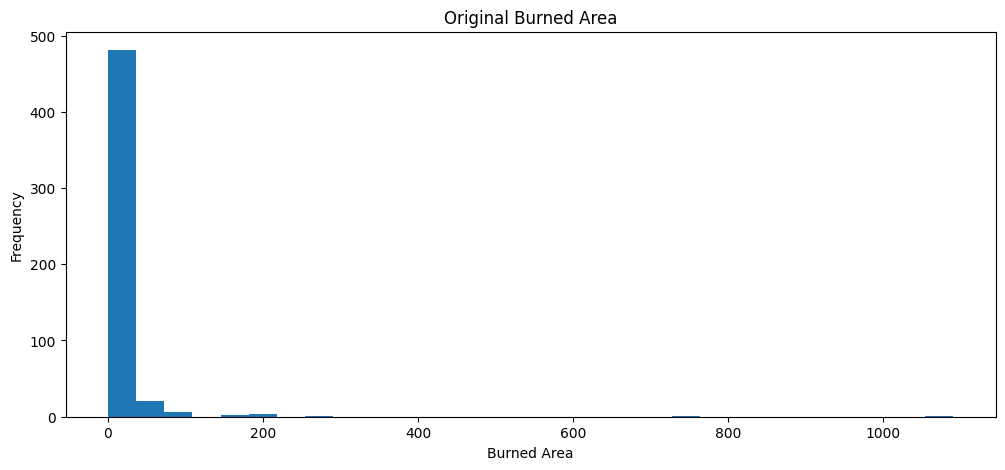

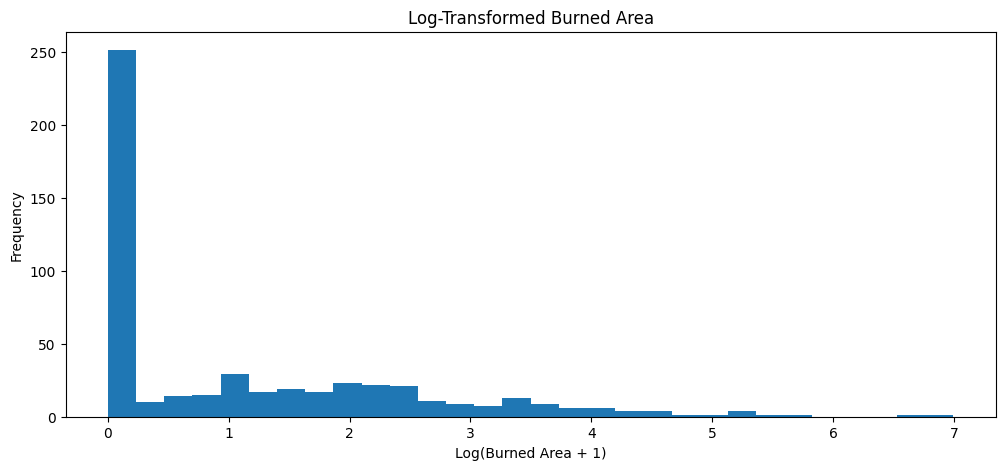

In [ ]:
# Compare the original and log-transformed target
plt.figure(figsize=(12, 5))

plt.hist(y["area"], bins=30)
plt.xlabel("Burned Area")
plt.ylabel("Frequency")
plt.title("Original Burned Area")

plt.show()

plt.figure(figsize=(12, 5))

plt.hist(y_log, bins=30)
plt.xlabel("Log(Burned Area + 1)")
plt.ylabel("Frequency")
plt.title("Log-Transformed Burned Area")

plt.show()

The original burned area data is highly skewed with many small values and a few very large values, the log transformation reduces this skewness and makes the distribution more balanced which may help improve the regression model.

### Step 4: Evaluate model diagnostics

* Compare models using metrics like 2R^2, adjusted RR^2, AIC, and BIC.
* Plot residuals and create Q-Q plots to assess normality.
* Identify influential observations using Cook's Distance.

In [ ]:
from sklearn.metrics import r2_score

In [ ]:
def model_metrics(y_actual, y_predicted, number_of_predictors):
    r2 = r2_score(y_actual, y_predicted)

    n = len(y_actual)
    adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - number_of_predictors - 1))

    return r2, adjusted_r2

In [ ]:
# Baseline model metrics
baseline_r2, baseline_adj_r2 = model_metrics(
    y["area"],
    baseline_predictions,
    X_numeric.shape[1]
)

# Nonlinear model metrics
nonlinear_r2, nonlinear_adj_r2 = model_metrics(
    y["area"],
    nonlinear_predictions,
    X_nonlinear.shape[1]
)

# Interaction model metrics
interaction_r2, interaction_adj_r2 = model_metrics(
    y["area"],
    interaction_predictions,
    X_interaction.shape[1]
)

# Categorical model metrics
categorical_r2, categorical_adj_r2 = model_metrics(
    y["area"],
    categorical_predictions,
    X_with_categories.shape[1]
)

print("Baseline R²:", baseline_r2)
print("Baseline Adjusted R²:", baseline_adj_r2)

print("\nNonlinear R²:", nonlinear_r2)
print("Nonlinear Adjusted R²:", nonlinear_adj_r2)

print("\nInteraction R²:", interaction_r2)
print("Interaction Adjusted R²:", interaction_adj_r2)

print("\nCategorical R²:", categorical_r2)
print("Categorical Adjusted R²:", categorical_adj_r2)

Baseline R²: 0.021639831514046137
Baseline Adjusted R²: 0.002304650318671553

Nonlinear R²: 0.02607424287649307
Nonlinear Adjusted R²: -0.001087033218584832

Interaction R²: 0.026886175460386852
Interaction Adjusted R²: 0.00173611637685811

Categorical R²: 0.04578209650808529
Categorical Adjusted R²: -0.006904781598830123


The R² values are low for all models, showing that the predictors explain only a small amount of the variation in burned area. The categorical model has the highest R² (0.046), but its negative adjusted R² suggests that the added complexity does not significantly improve the model.

 Overall, the results indicate that these linear models have limited ability to predict burned area.

In [ ]:
import statsmodels.api as sm

In [ ]:
# Add a constant/intercept
X_sm = sm.add_constant(X_numeric)

# Fit statsmodels model
baseline_sm = sm.OLS(y["area"], X_sm).fit()

print("Baseline AIC:", baseline_sm.aic)
print("Baseline BIC:", baseline_sm.bic)

Baseline AIC: 5771.58027517703
Baseline BIC: 5818.3087467966225


In [ ]:
X_nonlinear_sm = sm.add_constant(X_nonlinear)

nonlinear_sm = sm.OLS(
    y["area"],
    X_nonlinear_sm
).fit()

print("Nonlinear AIC:", nonlinear_sm.aic)
print("Nonlinear BIC:", nonlinear_sm.bic)

Nonlinear AIC: 5777.23164930518
Nonlinear BIC: 5840.952292422807


The nonlinear model has an AIC of 5777.23 and a BIC of 5840.95 these values are mainly useful when comparing this model with other models where lower AIC and BIC values generally indicate a better balance between model fit and complexity.

In [ ]:
X_interaction_sm = sm.add_constant(X_interaction)

interaction_sm = sm.OLS(
    y["area"],
    X_interaction_sm
).fit()

print("Interaction AIC:", interaction_sm.aic)
print("Interaction BIC:", interaction_sm.bic)

Interaction AIC: 5774.800462210518
Interaction BIC: 5834.273062453636


The interaction model has an AIC of 5774.80 and a BIC of 5834.27.

Compared with the nonlinear model, both values are slightly lower suggesting that the interaction model provides a slightly better balance between model fit and complexity.

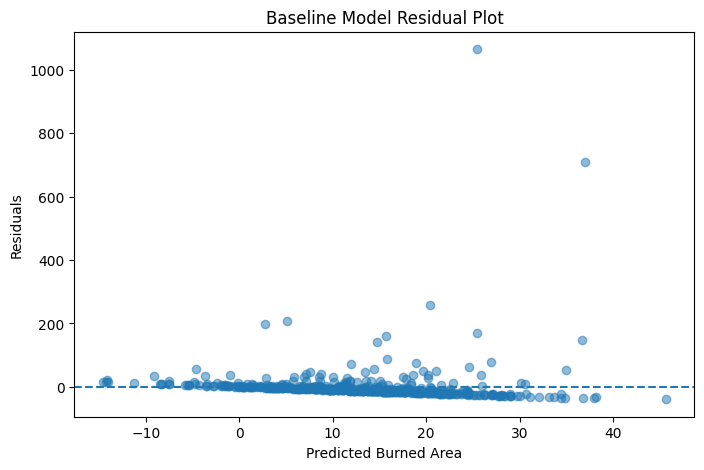

In [ ]:
# Calculate baseline residuals
baseline_residuals = y["area"] - baseline_predictions

plt.figure(figsize=(8, 5))

plt.scatter(
    baseline_predictions,
    baseline_residuals,
    alpha=0.5
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Burned Area")
plt.ylabel("Residuals")
plt.title("Baseline Model Residual Plot")

plt.show()

The residual plot helps assess whether the errors are randomly distributed around zero.

 Any clear patterns or extreme values would suggest that the baseline linear regression model may not fully capture the relationship between the predictors and burned area.

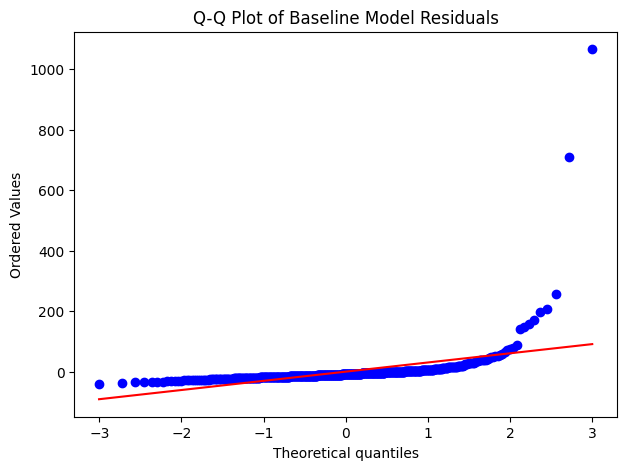

In [ ]:
import scipy.stats as stats

plt.figure(figsize=(7, 5))

stats.probplot(
    baseline_residuals,
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Baseline Model Residuals")

plt.show()

The points deviate significantly from the reference line especially in the upper tail where several extreme values are visible, this suggests that the residuals are not normally distributed and that there may be outliers caused by very large burned areas.

  This supports the use of a log transformation to reduce the effect of extreme values.

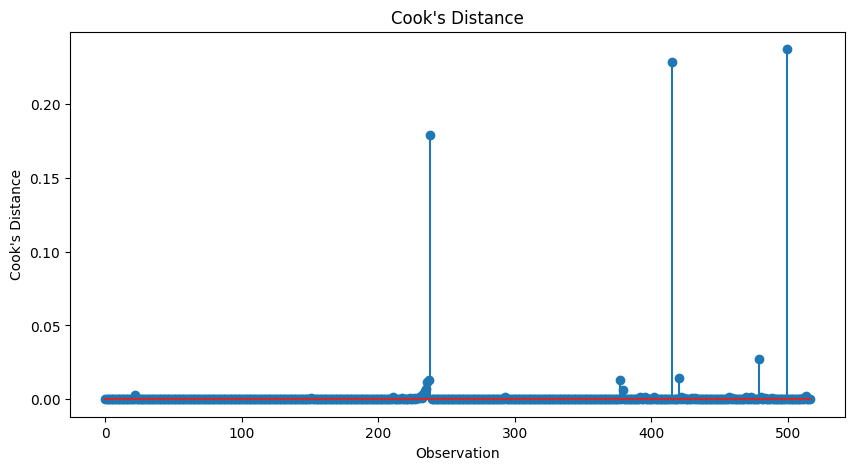

In [ ]:
# Get influence measures
influence = baseline_sm.get_influence()

# Calculate Cook's Distance
cooks_distance = influence.cooks_distance[0]

# Plot Cook's Distance
plt.figure(figsize=(10, 5))

plt.stem(
    range(len(cooks_distance)),
    cooks_distance
)

plt.xlabel("Observation")
plt.ylabel("Cook's Distance")
plt.title("Cook's Distance")

plt.show()

The Cook's Distance plot shows a few observations with much higher values than the rest particularly around observations 240, 415 and 500.

 These observations may be influential outliers that have a strong effect on the regression model,this should be considered when interpreting the model results.

In [ ]:
# Find the 10 observations with the largest Cook's Distance
top_influential = np.argsort(cooks_distance)[-10:]

print("Most influential observations:")
print(top_influential)

print("\nCook's Distance values:")
print(cooks_distance[top_influential])

Most influential observations:
[379 235 236 237 377 420 479 238 415 499]

Cook's Distance values:
[0.00636069 0.00701072 0.01168977 0.01276261 0.0128967  0.01454147
 0.02757708 0.17923767 0.22884643 0.23725634]


Observations 238, 415 and 499 have the highest Cook's Distance values meaning they strongly influence the regression model.

### Step 5: Apply regularization

* Use Ridge (L2) and Lasso (L1) regression from sklearn to handle multicollinearity.
* Extract coefficients and calculate Mean Squared Error (MSE).
* Compare the performance of Ridge and Lasso models.

In [ ]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_numeric,
    y["area"],
    test_size=0.2,
    random_state=42
)

# Scale predictors
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Create Ridge model
ridge_model = Ridge(alpha=1.0)

# Fit model
ridge_model.fit(X_train_scaled, y_train)

# Predictions
ridge_predictions = ridge_model.predict(X_test_scaled)

# Calculate MSE
ridge_mse = mean_squared_error(
    y_test,
    ridge_predictions
)

print("Ridge MSE:", ridge_mse)

Ridge MSE: 11759.696470196677


In [ ]:
# Ridge coefficients
ridge_coefficients = pd.DataFrame({
    "Feature": X_numeric.columns,
    "Coefficient": ridge_model.coef_
})

print(ridge_coefficients)

  Feature  Coefficient
0       X     4.889733
1       Y     0.086729
2    FFMC    -0.581834
3     DMC     7.226007
4      DC    -2.550277
5     ISI    -1.153088
6    temp     2.338585
7      RH    -3.147209
8    wind     1.500482
9    rain    -0.809052


DMC has the largest positive coefficient (7.23), while RH has a relatively strong negative coefficient (-3.15) suggesting these variables have stronger relationships with burned area in the Ridge model.

In [ ]:
# Create Lasso model
lasso_model = Lasso(alpha=0.1)

# Fit model
lasso_model.fit(X_train_scaled, y_train)

# Predictions
lasso_predictions = lasso_model.predict(X_test_scaled)

# Calculate MSE
lasso_mse = mean_squared_error(
    y_test,
    lasso_predictions
)

print("Lasso MSE:", lasso_mse)

Lasso MSE: 11762.490954649216


In [ ]:
# Lasso coefficients
lasso_coefficients = pd.DataFrame({
    "Feature": X_numeric.columns,
    "Coefficient": lasso_model.coef_
})

print(lasso_coefficients)

  Feature  Coefficient
0       X     4.818307
1       Y     0.052723
2    FFMC    -0.447318
3     DMC     6.903202
4      DC    -2.268709
5     ISI    -0.996322
6    temp     2.140217
7      RH    -3.049696
8    wind     1.359861
9    rain    -0.700661


Lasso model also shows DMC as having the largest positive coefficient (6.90) while RH has a strong negative coefficient (-3.05).

In [ ]:
print("Ridge MSE:", ridge_mse)
print("Lasso MSE:", lasso_mse)

Ridge MSE: 11759.696470196677
Lasso MSE: 11762.490954649216


In [ ]:
comparison = pd.DataFrame({
    "Model": ["Ridge", "Lasso"],
    "MSE": [ridge_mse, lasso_mse]
})

comparison

,Model,MSE
0,Ridge,11759.696470
1,Lasso,11762.490955


Ridge regression had a slightly lower MSE (11,759.70) than Lasso regression (11,762.49) indicating that Ridge performed marginally better.

### Step 6: Prepare the data for binary classification

* Create a binary target variable based on a threshold in y (e.g., median or other percentile).
* Select relevant predictors and scale them using StandardScaler.

In [ ]:
# Find the median burned area
area_median = y["area"].median()

print("Median burned area:", area_median)

Median burned area: 0.52


The median burned area is 0.52 which was used as the threshold to create the binary target variable. Fires with an area above this value were classified as larger fires while those at or below it were classified as smaller fires.

In [ ]:
# Create binary target variable
y_binary = (y["area"] > area_median).astype(int)

# Check the number of observations in each class
print(y_binary.value_counts())

area
0    259
1    258
Name: count, dtype: int64


In [ ]:
# Use the numerical predictors
X_classification = X_numeric.copy()

print("Classification predictors:")
print(X_classification.columns.tolist())

Classification predictors:
['X', 'Y', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']


In [ ]:
# Split data into training and testing sets
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_classification,
    y_binary,
    test_size=0.2,
    random_state=42,
    stratify=y_binary
)

print("Training observations:", X_train_class.shape[0])
print("Testing observations:", X_test_class.shape[0])

Training observations: 413
Testing observations: 104


In [ ]:
# Create the scaler
scaler_classification = StandardScaler()

# Fit the scaler on the training data and transform it
X_train_scaled = scaler_classification.fit_transform(X_train_class)

# Transform the test data using the same scaler
X_test_scaled = scaler_classification.transform(X_test_class)

print("Data scaling completed.")

Data scaling completed.


### Step 7: Train and evaluate a logistic regression model

Train a logistic regression model using the scaled predictors.

* Display coefficients and the intercept.
* Predict probabilities and binary outcomes.
* Evaluate performance using accuracy, confusion matrix, precision, recall, and F1-score.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

In [ ]:
# Create the logistic regression model
logistic_model = LogisticRegression(max_iter=1000)

# Train the model
logistic_model.fit(X_train_scaled, y_train_class)

print("Logistic regression model trained successfully.")

Logistic regression model trained successfully.


In [ ]:
# Display intercept
print("Intercept:", logistic_model.intercept_)

# Create a table of coefficients
logistic_coefficients = pd.DataFrame({
    "Feature": X_classification.columns,
    "Coefficient": logistic_model.coef_[0]
})

print("\nLogistic Regression Coefficients:")
display(logistic_coefficients)

Intercept: [-0.00826117]

Logistic Regression Coefficients:


,Feature,Coefficient
0,X,0.155747
1,Y,0.010987
2,FFMC,0.169859
3,DMC,0.043495
4,DC,0.152687
5,ISI,-0.182922
6,temp,-0.048336
7,RH,-0.116873
8,wind,0.136601
9,rain,0.065238


In [ ]:
# Predict probabilities of belonging to class 1
y_probabilities = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("First 10 predicted probabilities:")
print(y_probabilities[:10])

First 10 predicted probabilities:
[0.45598873 0.50546759 0.52152572 0.40051717 0.44690979 0.45473805
 0.45012738 0.43779314 0.53655988 0.51444105]


The first 10 predicted probabilities range from 0.40 to 0.54 with most values being close to 0.50 indicating that the model is relatively uncertain when classifying the observations.

In [ ]:
# Predict binary classes
y_pred_class = logistic_model.predict(X_test_scaled)

print("First 10 predictions:")
print(y_pred_class[:10])

First 10 predictions:
[0 1 1 0 0 0 0 0 1 1]


The first 10 predictions classify 6 observations as smaller fires (0) and 4 observations as larger fires (1).

In [ ]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test_class, y_pred_class)
precision = precision_score(y_test_class, y_pred_class)
recall = recall_score(y_test_class, y_pred_class)
f1 = f1_score(y_test_class, y_pred_class)

# Confusion matrix
conf_matrix = confusion_matrix(y_test_class, y_pred_class)

# Display results
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

print("\nConfusion Matrix:")
print(conf_matrix)

Accuracy: 0.5
Precision: 0.5
Recall: 0.4807692307692308
F1-score: 0.49019607843137253

Confusion Matrix:
[[27 25]
 [27 25]]


The classification model achieved 50% accuracy with a precision of 50%, recall of 48.08% and F1-score of 49.02%. The confusion matrix shows that the model correctly classified 52 out of 104 observations indicating that the model has limited ability to distinguish between smaller and larger burned-area fires using the selected predictors.


* Use Variance Inflation Factor (VIF) to assess multicollinearity among predictors.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [ ]:
# Create a copy of the numerical predictors
X_vif = X_numeric.copy()

# Add a constant
X_vif = sm.add_constant(X_vif)

# Create a DataFrame to store VIF values
vif_data = pd.DataFrame()

vif_data["Feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

display(vif_data)

,Feature,VIF
0,const,507.885686
1,X,1.433429
2,Y,1.445610
3,FFMC,1.698060
4,DMC,2.361567
5,DC,2.125930
6,ISI,1.579370
7,temp,2.666717
8,RH,1.913799
9,wind,1.142779


VIF results show that all predictor variables have VIF values below 5 indicating no serious multicollinearity among the features, therefore multicollinearity is not a major concern for the model.

### Step 9: Summative Findings

* Compare regression models and classification results.
* Highlight trade-offs between model simplicity, performance, and interpretability.
* Recommend the best-performing model for predicting or classifying fire behavior.

This analysis looked at regression and classification methods to understand and predict how forest fires behave. The basic multiple linear regression model gave a first step for estimating burned area from weather numbers and fire‑related variables. Later more models were built by adding terms interaction terms, categorical indicator variables and a logarithmic transformation of the burned area.

When we compared regression models with R², adjusted R², AIC and BIC we found that adding variables can make the fit better but a very complex model is not always the best. Adjusted R² AIC and BIC help us balance performance against higher complexity. We also looked at residual. Q‑q plots to see if the linear regression assumptions held. Cook’s Distance pointed out data points that had an influence on the regression model.

To deal with multicollinearity among predictors we used Ridge regression and Lasso regression. We compared their performance with Mean Squared Error. Ridge regression shrinks the size of coefficients. Keeps all predictors while Lasso regression can shrink less important coefficients to zero which may make the regression model easier to understand.

In classification we turned the burned area into an outcome that says whether the burned area is lower or higher. We then trained a regression model and assessed it with accuracy, precision, recall, F1‑score and a confusion matrix. These numbers tell us how well the logistic regression model can separate the two categories.

Overall the best model should be chosen according to the goal of the analysis. If the goal is to predict the burned area the regression model that shows the strongest performance metrics and keeps complexity reasonable will be chosen. If the goal is to classify fires into lower‑risk and higher‑risk categories logistic regression may be better. Model selection must look at performance, simplicity, interpretability, multicollinearity and how useful the predictions are in practice.